# ARIES Benchmark — Dataset Macro Analysis

> **Objetive:** Analize the [ARIES](https://aclanthology.org/2024.argmining-1.1/) benchmark dataset.

**Notebook's structure:**
> 0. Installation and setup
> 1. Loading and initial exploration of the CSV
> 2. Corpus size and composition

## 0. Installation and setup


In [1]:
# In VSCode: Ctrl+Shift+P → 'Python: Select Interpreter' select the environment you want to use, then run this script to install dependencies.
import subprocess, sys

PKGS = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'tabulate', 'nltk', 'tqdm']
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet'] + PKGS)
print('Dependencies installed')


Dependencies installed


In [2]:
# Global imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from pathlib import Path
from tabulate import tabulate
import ast
import csv as _csv
import warnings, re, json
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

# ── Plot style ──
sns.set_style('whitegrid')

plt.rcParams.update({
    'figure.facecolor': '#ffffff',
    'axes.facecolor':   '#ffffff',
    'axes.edgecolor':   '#000000',
    'axes.labelcolor':  '#000000',
    'xtick.color':      '#000000',
    'ytick.color':      '#000000',
    'text.color':       '#000000',
    'grid.color':       '#000000',
    'grid.linewidth':   0.5,
    'figure.dpi':       110,
})
PALETTE = ['#5b8dee','#7c5ce6','#3ecf8e','#f0a500','#f06060','#a29bfe']

print('Imports OK')


Imports OK


---
## 1. Loading and initial exploration of the CSV

ARIES benchmark evaluates the Argument Relation Identification (ARI) task as **a 3-class classification problem between two or more ADU**.

They consider the following 3 relation types:

> - Neutral: no relation exists
> - Inference: support relation
> - Conflict: attack relation


ARIES data includes 8 data sources from different domains:

| Dataset  | Domain                  | Ref.                       |
|----------|-------------------------|----------------------------|
| MTC      | Structured Argumentation|(Peldszus and Stede, 2015)  |
| AAEC     | Essay                   |(Stab and Gurevych, 2017)   |
| CDCP     | Financial               |(Park and Cardie, 2018)     |
| ACSP     | Scientific              |(Lauscher et al., 2018)     |
| AMP      | Online                  |(Chakrabarty et al., 2019)  |
| ABSTRCT  | Medical                 |(Mayer et al., 2020)        |
| US2016   | Political               |(Visser et al., 2020)       |
| QT30     | Question Answering      |(Hautli-Janisz et al., 2022)|


In [27]:
# CONFIGURE the path to your CSV HERE
CSV_PATH = '../data/aries/data.csv'

# Load CSV into a DataFrame
df = pd.read_csv(CSV_PATH, sep=',', dtype=str, keep_default_na=False)
df = df.replace('', np.nan)

print(f'Dataset with {len(df):,} Rows and {len(df.columns)} Columns.')
df.head(3)


Dataset with 76,987 Rows and 8 Columns.


,Unnamed: 0,data_source,argument,proposition_1,proposition_2,relations,start_end_indexes,all_relations
0,0,ACSP,humans are exceptionally sensitive to the sli...,and statistical methods,would typically require a very large database...,1,"[(2693, 2707)]",[('would typically require a very large databa...
1,1,ACSP,19 '[SEP]' The problem of simulating the beha...,By modifying the significance of this componen...,the topology has been modified,0,"[(1351, 1352)]","[('Figure 4', 'Default Inference')]"
2,2,ACSP,Several challenges remain '[SEP]' An optimiza...,Cohen and his colleagues,Liu et al. 1994,1,"[(625, 626), (637, 641)]","[('Cohen 1992', 'Default Inference'), ('Liu et..."


In [28]:
row = df.iloc[0]
print("argument: ", row['argument'])
print("proposition_1: ", row['proposition_1'])
print("proposition_2: ", row['proposition_2'])
print("relations: ", row['relations'])
print("all_relations: ", row['all_relations'])


argument:   humans are exceptionally sensitive to the slightest of errors '[SEP]' Authoring human motion is difficult for computer animators '[SEP]' In traditional keyframe animation '[SEP]' This process involves an animator providing a control specification which is mapped to a target motion by some means '[SEP]' advances in data acquisition technology and computational power '[SEP]' techniques have been developed that allow desired target motion to be specified using a human performance '[SEP]' it is essentially an identity mapping '[SEP]' Motion capture is the most direct method to map performances to animated humans '[SEP]' Bra99 '[SEP]' mapping voice signals to facial motion '[SEP]' a generalization of this approach to allow for more indirect mappings creates an array of fantastic possibilities '[SEP]' gestural actions to animated reactions '[SEP]' JP99 '[SEP]' this knowledge '[SEP]' The mapping from leader to follower motion must minimally encode a significant amount of knowledge

In [29]:
# ── Column Profile ──
def col_profile(df):
    rows = []
    for col in df.columns:
        s = df[col].dropna()
        nulls = df[col].isna().sum()
        uniq  = s.nunique()
        # infer type
        numeric = pd.to_numeric(s, errors='coerce').notna().mean() > .9
        type = 'numeric' if numeric else ('categorical' if uniq < 50 else 'text')
        sample_val = s.iloc[500][:80] if len(s) else ''
        rows.append({'column': col, 'type': type, 'uniques': uniq,
                     'nulls': nulls, '%nulls': f'{100*nulls/len(df):.1f}%',
                     'sample': sample_val})
    return pd.DataFrame(rows)

profile = col_profile(df)
print("Column Profile:")
print(tabulate(profile, headers='keys', tablefmt='rounded_outline', showindex=False))


Column Profile:
╭───────────────────┬─────────────┬───────────┬─────────┬──────────┬──────────────────────────────────────────────────────────────────────────────────╮
│ column            │ type        │   uniques │   nulls │ %nulls   │ sample                                                                           │
├───────────────────┼─────────────┼───────────┼─────────┼──────────┼──────────────────────────────────────────────────────────────────────────────────┤
│ Unnamed: 0        │ numeric     │     76987 │       0 │ 0.0%     │ 500                                                                              │
│ data_source       │ categorical │         8 │       0 │ 0.0%     │ AAEC                                                                             │
│ argument          │ text        │      2406 │       0 │ 0.0%     │ children should learn music and art in a young age '[SEP]' they do contribute s  │
│ proposition_1     │ text        │     15325 │       0 │ 0.0%     │ eve

In [30]:
# Instances (ADU) frequency per data_source
data_source_counts = df['data_source'].value_counts().reset_index()
data_source_counts.columns = ['data_source', 'ADU_pairs']

# Unique arguments per data_source
unique_args_per_source = df.groupby('data_source')['argument'].nunique().reset_index()
unique_args_per_source.columns = ['data_source', 'unique_arguments']

combined = data_source_counts.merge(unique_args_per_source, on='data_source')

# New column: ADU_pairs / unique_arguments
combined['pairs_per_argument'] = (combined['ADU_pairs'] / combined['unique_arguments']).round(0)

totals = {
    'data_source': 'TOTAL',
    'ADU_pairs': combined['ADU_pairs'].sum(),
    'unique_arguments': combined['unique_arguments'].sum(),
    'pairs_per_argument': (combined['ADU_pairs'].sum() / combined['unique_arguments'].sum()).round(0)
}

combined_with_totals = pd.concat([combined, pd.DataFrame([totals])], ignore_index=True)

print("\nData source distribution:")
print(tabulate(combined_with_totals, headers='keys', tablefmt='rounded_outline', showindex=False))



Data source distribution:
╭───────────────┬─────────────┬────────────────────┬──────────────────────╮
│ data_source   │   ADU_pairs │   unique_arguments │   pairs_per_argument │
├───────────────┼─────────────┼────────────────────┼──────────────────────┤
│ ACSP          │       26298 │                 40 │                  657 │
│ AAEC          │       16014 │                402 │                   40 │
│ US2016        │       10893 │                443 │                   25 │
│ Cuties        │        9777 │                680 │                   14 │
│ ABstRACT      │        7215 │                658 │                   11 │
│ US2016R1      │        3369 │                147 │                   23 │
│ CDCP          │        2328 │                 70 │                   33 │
│ Microtext     │        1093 │                112 │                   10 │
│ TOTAL         │       76987 │               2552 │                   30 │
╰───────────────┴─────────────┴────────────────────┴─────────

In [31]:
# Arguments with data_sources > 1
shared_args = df.groupby('argument')['data_source'].nunique()
shared_args = shared_args[shared_args > 1]
print(f"Shared arguments: {len(shared_args)}")


Shared arguments: 146


In [32]:
arg_sources = df.groupby('argument')['data_source'].unique().reset_index()

# Arguments that appear in more than one data_source
shared_args = arg_sources[arg_sources['data_source'].apply(len) > 1]

shared_args['num_sources'] = shared_args['data_source'].apply(len)

shared_args['data_source'] = shared_args['data_source'].apply(lambda x: ", ".join(x))

# sort by number of sources
shared_args = shared_args.sort_values('num_sources', ascending=False)

print(shared_args.shape)
# Show first 10
print("\nShared arguments across data sources (top 10):")
print(tabulate(shared_args.head(10), headers='keys', tablefmt='rounded_outline', showindex=False))


(146, 3)

Shared arguments across data sources (top 10):
╭──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

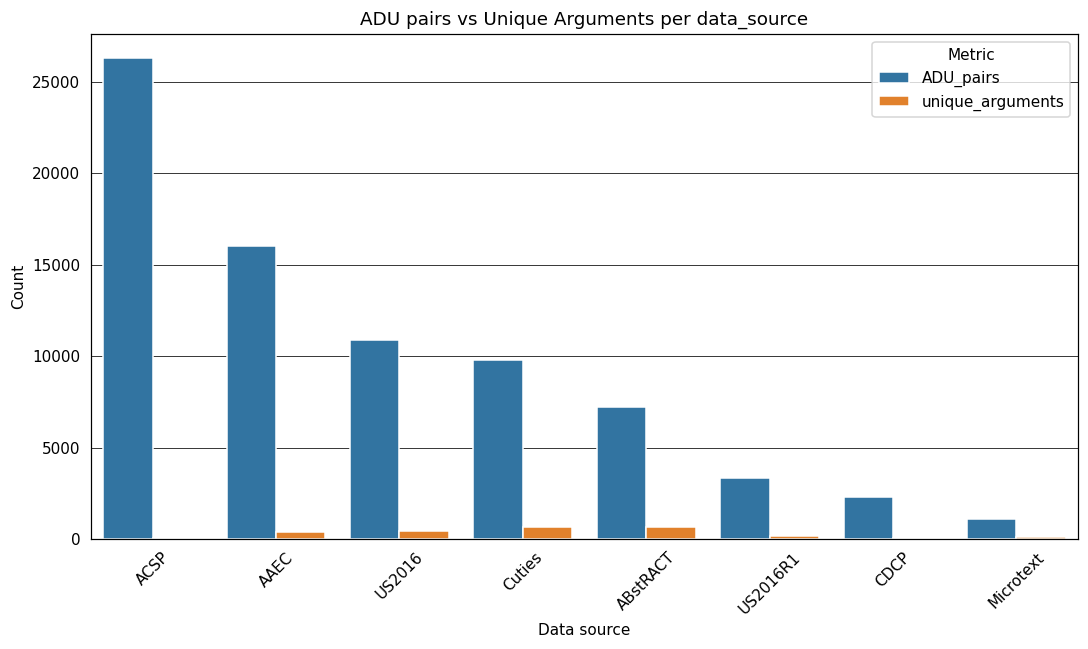

In [33]:
# Datasource distribution plot
plt.figure(figsize=(10,6))

# combined = combined[combined['data_source']!='ACSP']

plot_data = combined.melt(id_vars='data_source', 
                          value_vars=['ADU_pairs','unique_arguments'], 
                          var_name='Metric', 
                          value_name='Count')

sns.barplot(x='data_source', y='Count', hue='Metric', data=plot_data)

plt.title("ADU pairs vs Unique Arguments per data_source")
plt.xlabel("Data source")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()


> ACSP domains the dataset with 26298 pairs and only unique 40 arguments.

In [34]:
relations_counts = df['relations'].value_counts().reset_index()
relations_counts.columns = ['relations', 'frequency']
print("\nRelation distribution:\nNeutral: 0\nInference:1\nConflict:2")
print(tabulate(relations_counts, headers='keys', tablefmt='rounded_outline', showindex=False))




Relation distribution:
Neutral: 0
Inference:1
Conflict:2
╭─────────────┬─────────────╮
│   relations │   frequency │
├─────────────┼─────────────┤
│           0 │       51080 │
│           1 │       22518 │
│           2 │        3389 │
╰─────────────┴─────────────╯


In [35]:
relations_per_source = df.groupby(['relations','data_source']).size().reset_index(name='frequency')

relations_pivot = relations_per_source.pivot(index='data_source', columns='relations', values='frequency').fillna(0).astype(int)

print("\nRelations distribution per dataset:")
print(tabulate(relations_pivot.reset_index(), headers='keys', tablefmt='rounded_outline', showindex=False))



Relations distribution per dataset:
╭───────────────┬───────┬──────┬─────╮
│ data_source   │     0 │    1 │   2 │
├───────────────┼───────┼──────┼─────┤
│ AAEC          │ 10676 │ 4841 │ 497 │
│ ABstRACT      │  4581 │ 2290 │ 344 │
│ ACSP          │ 17532 │ 8069 │ 697 │
│ CDCP          │  1552 │  694 │  82 │
│ Cuties        │  6518 │ 2714 │ 545 │
│ Microtext     │   713 │  272 │ 108 │
│ US2016        │  7262 │ 2765 │ 866 │
│ US2016R1      │  2246 │  873 │ 250 │
╰───────────────┴───────┴──────┴─────╯


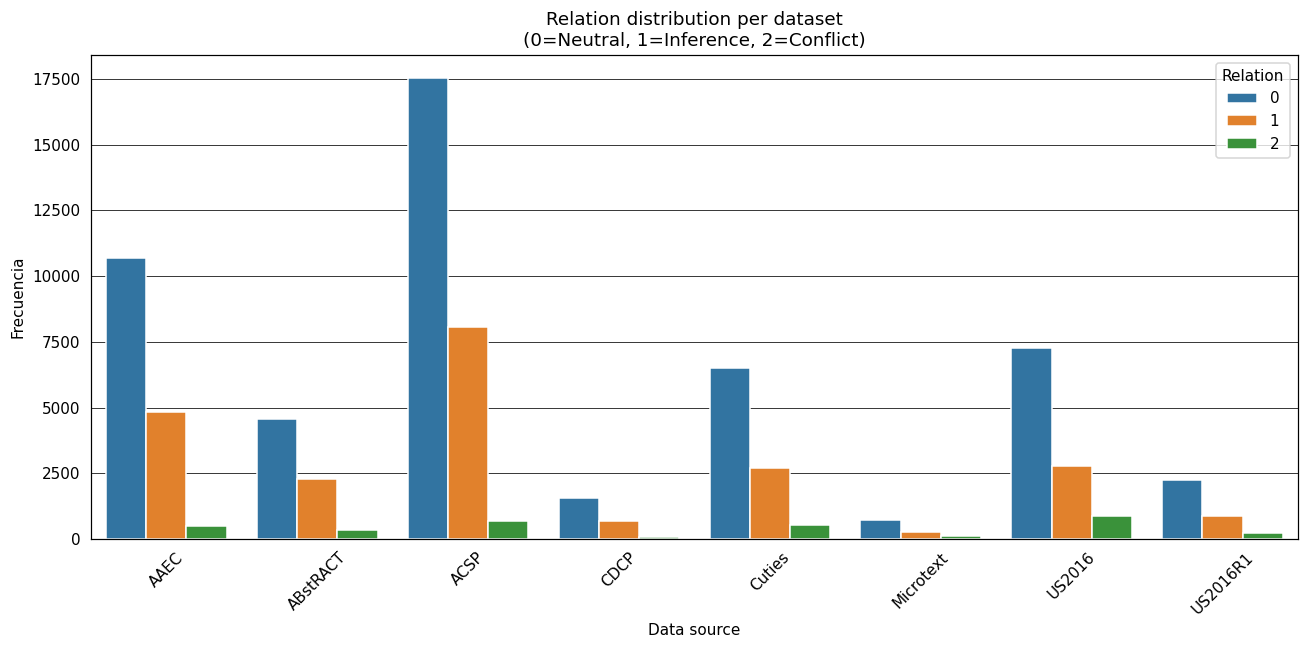

In [36]:
plot_data = relations_pivot.reset_index().melt(
    id_vars='data_source',   
    var_name='relations',    
    value_name='frequency'   
)

plt.figure(figsize=(12,6))
sns.barplot(x='data_source', y='frequency', hue='relations', data=plot_data)

plt.title("Relation distribution per dataset\n(0=Neutral, 1=Inference, 2=Conflict)")
plt.xlabel("Data source")
plt.ylabel("Frecuencia")
plt.xticks(rotation=45)
plt.legend(title='Relation')
plt.tight_layout()
plt.show()


### Dataset statistics


In the dataset, each row represents a relationship between a pair of ADUs:

| argument | proposition_1 | proposition_2 | relation |

> Global statistics: 


In [37]:
# Pairs distribution per argument
pairs_per_arg = df.groupby('argument').size()
global_stats = pairs_per_arg.describe().round(0).reset_index()
global_stats.columns = ['statistic', 'value']

print("ADU pairs per argument:")
print(tabulate(global_stats, headers='keys', tablefmt='rounded_outline', showindex=False))


ADU pairs per argument:
╭─────────────┬─────────╮
│ statistic   │   value │
├─────────────┼─────────┤
│ count       │    2406 │
│ mean        │      32 │
│ std         │     106 │
│ min         │       1 │
│ 25%         │       5 │
│ 50%         │      10 │
│ 75%         │      23 │
│ max         │    1877 │
╰─────────────┴─────────╯


> Statistics per source:

In [38]:
# Pairs per argument and data_source
pairs_per_arg_source = df.groupby(['data_source','argument']).size().reset_index(name='pairs')

stats_per_source = pairs_per_arg_source.groupby('data_source')['pairs'].describe().round(0).reset_index()

print("\nPairs per argument statistics by data_source:")
# print(stats_per_source)
print(tabulate(stats_per_source, headers='keys', tablefmt='rounded_outline', showindex=False))



Pairs per argument statistics by data_source:
╭───────────────┬─────────┬────────┬───────┬───────┬───────┬───────┬───────┬───────╮
│ data_source   │   count │   mean │   std │   min │   25% │   50% │   75% │   max │
├───────────────┼─────────┼────────┼───────┼───────┼───────┼───────┼───────┼───────┤
│ AAEC          │     402 │     40 │    19 │     9 │    26 │    35 │    50 │   125 │
│ ABstRACT      │     658 │     11 │     9 │     2 │     4 │     8 │    14 │    84 │
│ ACSP          │      40 │    657 │   339 │   236 │   396 │   586 │   870 │  1877 │
│ CDCP          │      70 │     33 │    52 │     1 │    10 │    20 │    34 │   346 │
│ Cuties        │     680 │     14 │    78 │     1 │     4 │     6 │    10 │  1733 │
│ Microtext     │     112 │     10 │     6 │     3 │     5 │    10 │    12 │    50 │
│ US2016        │     443 │     25 │    47 │     1 │     3 │     8 │    18 │   279 │
│ US2016R1      │     147 │     23 │    43 │     1 │     3 │     7 │    18 │   260 │
╰───────────────┴─

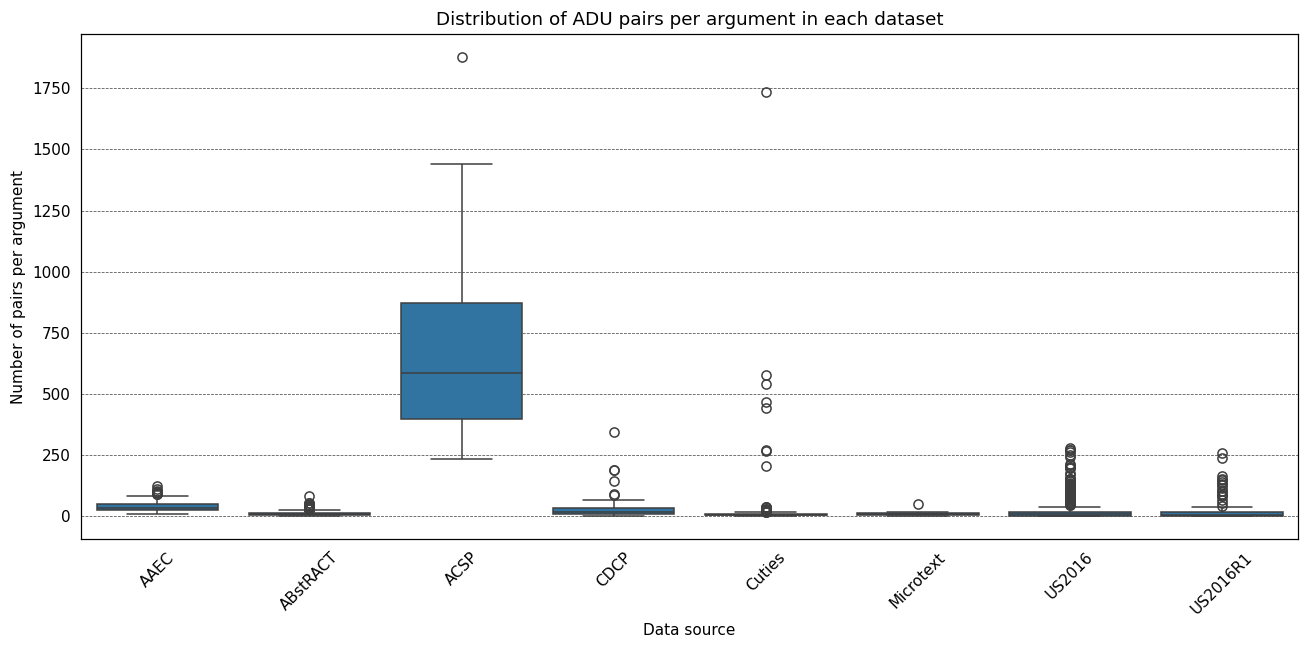

In [39]:
plt.figure(figsize=(12,6))
sns.boxplot(x='data_source', y='pairs', data=pairs_per_arg_source)

plt.title("Distribution of ADU pairs per argument in each dataset")
plt.xlabel("Data source")
plt.ylabel("Number of pairs per argument")
plt.xticks(rotation=45)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### Sample Argument

In [40]:
sample_arg = df['argument'].value_counts().index[1000]
sample_subset=df[df['argument'] == sample_arg]
print("Shape of sample subset:", sample_subset.shape)
sample_subset


Shape of sample subset: (12, 8)


,Unnamed: 0,data_source,argument,proposition_1,proposition_2,relations,start_end_indexes,all_relations
3256,3256,Microtext,"Considering what's on television these days, ...","Considering what's on television these days, i...","That shouldn't be an issue though, given the ...",0,"[(36, 59), (75, 90), (94, 124)]",[('In some cases there are only shows for olde...
7435,7435,Microtext,"Considering what's on television these days, ...","Considering what's on television these days, i...",Nevertheless one has to point out that there'...,2,"[(36, 59), (75, 90), (94, 124)]",[('In some cases there are only shows for olde...
9332,9332,Microtext,"Considering what's on television these days, ...",so there's no advantage for the current paying...,"By now you have advertising on all channels,",1,"[(63, 71)]",[('By now you have advertising on all channels...
15531,15531,Microtext,"Considering what's on television these days, ...","Considering what's on television these days, i...",so there's no advantage for the current payin...,1,"[(36, 59), (75, 90), (94, 124)]",[('In some cases there are only shows for olde...
24558,24558,Microtext,"Considering what's on television these days, ...","Considering what's on television these days, i...",In some cases there are only shows for older ...,1,"[(36, 59), (75, 90), (94, 124)]",[('In some cases there are only shows for olde...
27019,27019,Microtext,"Considering what's on television these days, ...","Considering what's on television these days, i...","Considering what's on television these days, ...",0,"[(36, 59), (75, 90), (94, 124)]",[('In some cases there are only shows for olde...
31031,31031,Microtext,"Considering what's on television these days, ...",so there's no advantage for the current paying...,In some cases there are only shows for older ...,0,"[(63, 71)]",[('By now you have advertising on all channels...
40075,40075,Microtext,"Considering what's on television these days, ...","Considering what's on television these days, i...","By now you have advertising on all channels,",0,"[(36, 59), (75, 90), (94, 124)]",[('In some cases there are only shows for olde...
51890,51890,Microtext,"Considering what's on television these days, ...",so there's no advantage for the current paying...,"Considering what's on television these days, ...",0,"[(63, 71)]",[('By now you have advertising on all channels...
62429,62429,Microtext,"Considering what's on television these days, ...",so there's no advantage for the current paying...,"That shouldn't be an issue though, given the ...",0,"[(63, 71)]",[('By now you have advertising on all channels...


> Considering what's on television these days, it would be appropriate to only have those people pay who actually (want to) follow the programming. **'[SEP]'** In some cases there are only shows for older generations on at prime times, so why then should everyone pay for this? **'[SEP]'** By now you have advertising on all channels, **'[SEP]'** so there's no advantage for the current paying viewers of the public broadcasters. **'[SEP]'** Nevertheless one has to point out that there'd probably be way fewer stations if it weren’t the whole of Germany that’s obliged to pay. **'[SEP]'** That shouldn't be an issue though, given the sheer number of programmes and stations that essentially show the same things anyway.



In [41]:
# Relations dictionary
relations_dict = {
    0: "Neutral", 0: "Default Neutral",
    1: "Inference", 1: "Default Inference",
    2: "Conflict", 2: "Default Conflict"
}


In [42]:
def get_sentences_from_argument(sample_arg, split_char='[SEP]'):
    """
    Given a sample argument string, split it into individual sentences based on the specified split character.
    Returns a dictionary mapping sentence keys (S1, S2, ...) to their corresponding sentences.
    """
    sample_sentences = sample_arg.split(f"'{split_char}'")
    dic_sentences = {f"S{i+1}": sentence.strip() for i, sentence in enumerate(sample_sentences)}

    print("Sample Sentences Dictionary:")
    for key, sentence in dic_sentences.items():
        print(f"{key}: {sentence}")
    
    return dic_sentences

dic_sentences = get_sentences_from_argument(sample_arg)


Sample Sentences Dictionary:
S1: Considering what's on television these days, it would be appropriate to only have those people pay who actually (want to) follow the programming.
S2: In some cases there are only shows for older generations on at prime times, so why then should everyone pay for this?
S3: By now you have advertising on all channels,
S4: so there's no advantage for the current paying viewers of the public broadcasters.
S5: Nevertheless one has to point out that there'd probably be way fewer stations if it weren’t the whole of Germany that’s obliged to pay.
S6: That shouldn't be an issue though, given the sheer number of programmes and stations that essentially show the same things anyway.


In [43]:
map_sentence_to_S = {v.strip(): k for k, v in dic_sentences.items()}
map_rel_str_to_label = {v.strip(): k for k, v in relations_dict.items()}

def print_mapped_relations(row):
    src = map_sentence_to_S[row['proposition_1'].strip()]
    rel = row['relations']
    tgt = map_sentence_to_S[row['proposition_2'].strip()]

    mapped_all_relations = []
    for sent, r in eval(row['all_relations']):
        mapped_all_relations.append((map_sentence_to_S[sent.strip()], map_rel_str_to_label[str(r)]))

    print(f"{src} -- {rel} --> {tgt}  |  {mapped_all_relations}")


In [44]:
def print_arg_graph(data):
    """
    Given a DataFrame containing proposition pairs and their relations, print the mapped relations for each row.
    """
    for _, row in data.iterrows():
        print_mapped_relations(row)


In [45]:
data = df[df['argument'] == sample_arg][['proposition_1','relations','proposition_2','all_relations']]

print("\nMapped Relations for Sample Argument:")
print_arg_graph(data)


Mapped Relations for Sample Argument:
S1 -- 0 --> S6  |  [('S2', 1), ('S4', 1), ('S5', 2)]
S1 -- 2 --> S5  |  [('S2', 1), ('S4', 1), ('S5', 2)]
S4 -- 1 --> S3  |  [('S3', 1)]
S1 -- 1 --> S4  |  [('S2', 1), ('S4', 1), ('S5', 2)]
S1 -- 1 --> S2  |  [('S2', 1), ('S4', 1), ('S5', 2)]
S1 -- 0 --> S1  |  [('S2', 1), ('S4', 1), ('S5', 2)]
S4 -- 0 --> S2  |  [('S3', 1)]
S1 -- 0 --> S3  |  [('S2', 1), ('S4', 1), ('S5', 2)]
S4 -- 0 --> S1  |  [('S3', 1)]
S4 -- 0 --> S6  |  [('S3', 1)]
S4 -- 0 --> S5  |  [('S3', 1)]
S4 -- 0 --> S4  |  [('S3', 1)]


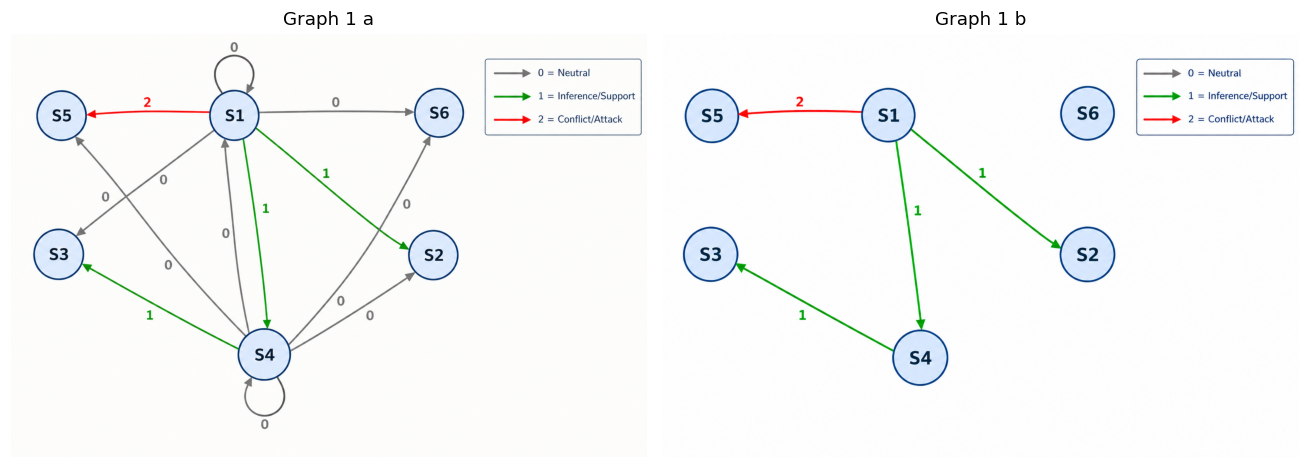

In [46]:
import matplotlib.image as mpimg

img1 = mpimg.imread('../assets/images/ChatGPT_g1_a.png')
img2 = mpimg.imread('../assets/images/ChatGPT_g1_b.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img1)
axes[0].axis('off')
axes[0].set_title("Graph 1 a")

axes[1].imshow(img2)
axes[1].axis('off')
axes[1].set_title("Graph 1 b")

plt.tight_layout()
plt.show()




---
## 2. Corpus size and composition


In [47]:
# ── Semantic column mapping ──
lower = {c: c.lower().replace(' ','_').replace('-','_') for c in df.columns}

def find_col(df, *terms):
    for t in terms:
        for col, lc in lower.items():
            if t in lc:
                return col
    return None

COL = {
    'text1':    find_col(df, 'proposition_1'), #'premise','adu1','arg1','text1','src',
    'text2':    find_col(df, 'proposition_2'), #'claim','conclusion','target','adu2','arg2','text2','tgt',
    'text':     find_col(df, 'argument'), #'text','content','sentence','utterance', 
    'relation': find_col(df, 'relation'), #,'label','rel','type','class'
    'dataset':  find_col(df, 'data'), #'dataset','corpus','domain', 
    'doc_id':   find_col(df, 'argument'), #'doc_id','document','essay','abstract','doc', 
    'pair_id':  find_col(df, 'id','idx','index','pair'),
}

# If text1 does not appear, use the generic 'text' column.
if not COL['text1'] and COL['text']:
    COL['text1'] = COL['text']

print('Semantic column mapping detected:')
for k, v in COL.items():
    status = '✓' if v else '✗ (not detected)'
    print(f'  {k:12s} → {v or "—"}  {status}')


Semantic column mapping detected:
  text1        → proposition_1  ✓
  text2        → proposition_2  ✓
  text         → argument  ✓
  relation     → relations  ✓
  dataset      → data_source  ✓
  doc_id       → argument  ✓
  pair_id      → start_end_indexes  ✓


In [48]:
# ── Helper: count tokens and sentences ──
def n_tokens(text):
    """
    Simple token estimation by splitting on whitespace. 
    Returns the number of tokens in the given text.
    """
    if not isinstance(text, str) or not text.strip():
        return 0
    return len(text.split())

def n_sents(text):
    """
    Simple sentence estimation by splitting on '[SEP]'.
    Returns the number of sentences in the given text.
    """
    if not isinstance(text, str) or not text.strip():
        return 0
    return max(1, len(re.split(r'\[SEP\]', text)))

### Sentence count by argument and data source

Simple splitting using the special token **'[SEP]'**

In [49]:
# Sentence counts per unique argument
sent_per_argument = (df.drop_duplicates('argument')['argument']
                 .apply(n_sents))

sent_per_argument_stats = sent_per_argument.describe().round(0).reset_index()
sent_per_argument_stats.columns = ['statistic', 'value']

print("Sentence counts per argument:")
print(tabulate(sent_per_argument_stats, headers='keys', tablefmt='rounded_outline', showindex=False))

Sentence counts per argument:
╭─────────────┬─────────╮
│ statistic   │   value │
├─────────────┼─────────┤
│ count       │    2406 │
│ mean        │      17 │
│ std         │      35 │
│ min         │       2 │
│ 25%         │       6 │
│ 50%         │      11 │
│ 75%         │      16 │
│ max         │     451 │
╰─────────────┴─────────╯


In [50]:
# Sentence counts per argument by data_source
sent_per_argument_source = df.groupby('data_source')['argument'].apply(lambda x: x.drop_duplicates().apply(n_sents)) 
sent_per_argument_source_stats = sent_per_argument_source.groupby('data_source').describe().round(0).reset_index()
print("\nSentence counts per argument by data_source:")
print(tabulate(sent_per_argument_source_stats, headers='keys', tablefmt='rounded_outline', showindex=False))


Sentence counts per argument by data_source:
╭───────────────┬─────────┬────────┬───────┬───────┬───────┬───────┬───────┬───────╮
│ data_source   │   count │   mean │   std │   min │   25% │   50% │   75% │   max │
├───────────────┼─────────┼────────┼───────┼───────┼───────┼───────┼───────┼───────┤
│ AAEC          │     402 │     15 │     4 │     7 │    12 │    15 │    18 │    28 │
│ ABstRACT      │     658 │      5 │     2 │     2 │     4 │     5 │     6 │    14 │
│ ACSP          │      40 │    250 │    70 │   151 │   193 │   238 │   299 │   451 │
│ CDCP          │      70 │     26 │    20 │     4 │    15 │    21 │    30 │   112 │
│ Cuties        │     680 │     16 │    17 │     4 │    11 │    14 │    17 │   287 │
│ Microtext     │     112 │      5 │     1 │     3 │     5 │     5 │     5 │    10 │
│ US2016        │     443 │     19 │    21 │     2 │     6 │    11 │    20 │   127 │
│ US2016R1      │     147 │     18 │    21 │     2 │     7 │    11 │    18 │   127 │
╰───────────────┴──

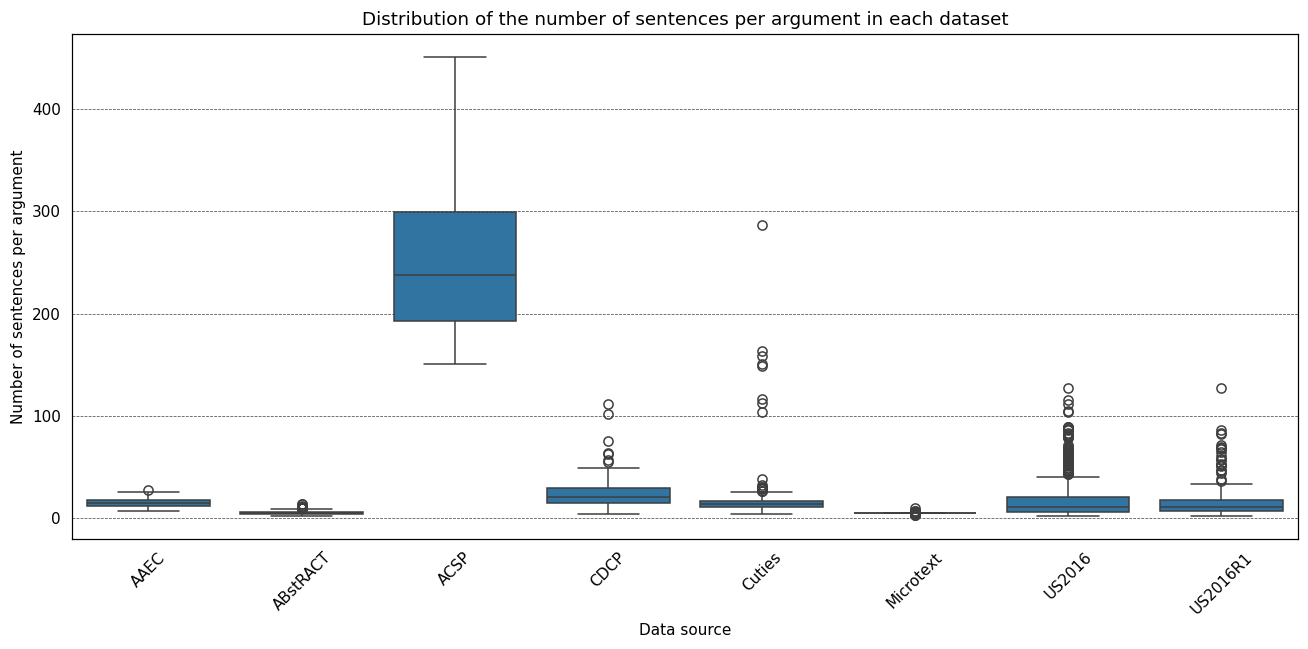

In [51]:
sent_df = sent_per_argument_source.reset_index(name='sentence_count')

# sent_df = sent_df[sent_df['data_source'] != 'ACSP']

plt.figure(figsize=(12,6))
sns.boxplot(x='data_source', y='sentence_count', data=sent_df)

plt.title("Distribution of the number of sentences per argument in each dataset")
plt.xlabel("Data source")
plt.ylabel("Number of sentences per argument")
plt.xticks(rotation=45)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


---
## Próximos pasos (Nivel 2)

Una vez completado este análisis macro, los siguientes notebooks abordarán:

| Nivel | Notebook | Contenido |
|---|---|---|
| **2** | `02_graph_analysis.ipynb` | Transformación a grafo (nodos, aristas, densidad, topología, constraints) |
| **3** | `03_component_analysis.ipynb` | Tipos de componentes, spans, cobertura, solapamientos |
| **4** | `04_relation_analysis.ipynb` | Distancia inter/intra-sentence, dirección, distribución por tipo |
| **5** | `05_modelling_features.ipynb` | Desbalance por sub-tarea, baselines, compatibilidad entre datasets |
